# Classify synthetic breast masses with client Kumo Tabular on Snowflake

Classify generated measurements into simulated `benign` and `malignant` labels through an existing Kumo Tabular NIM endpoint.
Run this client notebook with an active Snowflake session for the staged input; inference runs on the NIM server, so the notebook needs no GPU.
This synthetic example demonstrates the API and does not establish clinical performance. See [client predictions](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/make-predictions/make-predictions).

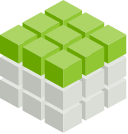

## Install and connect

Use a Python 3.10 or newer kernel with network access to the NIM endpoint and an active Snowflake session for the dataset. The notebook also uses pandas, NumPy, and scikit-learn.

Install the base client; the relational extra is not needed. See [Install and Connect](https://docs.nvidia.com/sdgm/kumo-tabular/get-started/sdk-getting-started).


In [ ]:
%pip install structured-data-models-client


## Set the example parameters

Set the NIM endpoint and API key through environment variables. Enter `stage_file` after uploading the generated CSV to your own Snowflake stage.
The seed controls generation and splitting; 4,000 labeled context rows stay below the client's 10,000-row limit. Each run retains its files in a new local directory.


In [ ]:
import os
from pathlib import Path
from tempfile import mkdtemp
import numpy as np
import pandas as pd
from sdm_client import SDMClient, KumoTabular, Request, Schema, PredictiveQuery

nim_endpoint = os.environ.get("KUMO_TABULAR_API_ENDPOINT", "")
nim_api_key = os.environ.get("KUMO_TABULAR_API_KEY")
stage_file = ""  # Your @database.schema.stage/breast_mass.csv
RANDOM_SEED = 42
ROW_COUNT = 20000
CONTEXT_ROWS = 4000
OUTPUT_PARENT = Path.cwd()

run_dir = Path(mkdtemp(prefix="client_mass_classification-", dir=OUTPUT_PARENT))
print("Retained run:", run_dir)


## Generate synthetic example data

Run the next cell to create a local CSV of invented `Age`, `Shape`, `Margin`, and `Density` measurements with noisy simulated labels.
Generation writes no Snowflake data. You can skim it; staging and context preparation follow.


In [ ]:
def breast_mass(seed, count):
    rng = np.random.default_rng(seed)
    n = count
    frame = pd.DataFrame({"Age": rng.uniform(20, 90, n).round(3), "Shape": rng.integers(1, 5, n), "Margin": rng.integers(1, 6, n), "Density": rng.uniform(1, 4, n).round(4)})
    risk = (frame.Age - 55) / 20 + (frame.Shape - 2.5) * 0.7 + (frame.Margin - 3) * 0.5
    frame["Severity"] = (rng.random(n) < 1 / (1 + np.exp(-risk))).astype(int)
    return frame

data = breast_mass(RANDOM_SEED, ROW_COUNT)
data_dir = run_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)
data.to_csv(data_dir / "breast_mass.csv", index=False)

print("Upload this file:", data_dir / "breast_mass.csv")


## Load your staged file

Manually upload the CSV at the printed path to your Snowflake stage, then set `stage_file` in the parameters cell to its `@database.schema.stage/breast_mass.csv` path.
The active Snowpark session supplies account authentication; the next cell only reads the staged file.


In [ ]:
from snowflake.snowpark.context import get_active_session
import io
if not stage_file:
    raise ValueError("Set stage_file after uploading the locally generated CSV")
session = get_active_session()
with session.file.get_stream(stage_file) as stream:
    data = pd.read_csv(io.BytesIO(stream.read()))


## Prepare labeled context

Use a stratified split to keep both generated classes in context and evaluation rows. Map the generated label to readable class names; scoring features will exclude it.


In [ ]:
from sklearn.model_selection import train_test_split
X = data[["Age", "Shape", "Margin", "Density"]]
y = data["Severity"].map({0: "benign", 1: "malignant"})
classes = sorted(y.unique())
df = X.assign(target=pd.Categorical(y, categories=classes))
# Bound labeled context below the client's 10,000-row limit.
train, test = train_test_split(data.index, train_size=CONTEXT_ROWS, stratify=y, random_state=RANDOM_SEED)

assert 1 < CONTEXT_ROWS <= 10000
assert set(train).isdisjoint(test)
print("Context rows:", len(train), "Held-out scoring rows:", len(test))


## Batch predictions

Build labeled `context` and a separate held-out `to_score` frame without targets. Keep original row IDs and declare the numerical/categorical feature types in the request schema.
See [client prediction requests](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/make-predictions/make-predictions) for the input contract.


In [ ]:
context = df.iloc[train].copy()
to_score = df.iloc[test].drop(columns="target").copy()
context.insert(0, "row_id", train)
to_score.insert(0, "row_id", test)

schema = Schema.from_data(
    {"masses": context},
    primary_keys={"masses": "row_id"},
    relationships=[],
)
for column, stype in {
    "Age": "numerical",
    "Density": "numerical",
    "Shape": "categorical",
    "Margin": "categorical",
    "target": "categorical",
}.items():
    schema["masses"][column].stype = stype
schema.check_consistent()

request = Request(
    context=context,
    predict=to_score,
    target="target",
    task="classification",
    schema=schema,
    entity_table="masses",
)


Send the prepared batch to the deployed Kumo Tabular model and request labels and class probabilities.


In [ ]:
if not nim_endpoint:
    raise ValueError("Set KUMO_TABULAR_API_ENDPOINT to your deployed NIM URL")

with SDMClient(url=nim_endpoint, api_key=nim_api_key) as client:
    result = client.predict(
        request,
        model=KumoTabular(),
        outputs=["prediction", "probabilities"],
    )


### Inspect and save predictions

Expect one result per input. `row_index` is the zero-based position in `to_score`, while `prediction` and `probability_<class>` contain the label and class probabilities.
Align on `row_index`, attach the original `row_id`, inspect a sample, and save the full batch. See [prediction results](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/work-with-prediction-results/prediction-results).


In [ ]:
raw_answers = result.to_pandas()
assert raw_answers.row_index.is_unique
assert set(raw_answers.row_index) == set(range(len(to_score)))
answers = raw_answers.set_index("row_index").loc[range(len(to_score))]
predictions = answers["prediction"].to_numpy()
probabilities = answers[[f"probability_{label}" for label in classes]].to_numpy()
assert len(to_score) >= 2 and "target" not in to_score
assert np.isfinite(probabilities).all()
np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-5)
answers.insert(0, "row_id", to_score.row_id.to_numpy())
print(answers.head(8).to_string(index=False))
output_path = run_dir / "predictions.csv"
answers.to_csv(output_path, index=False)
print("Saved:", output_path)


## Evaluate predictions

**Synthetic-data metrics — demonstration only.** Accuracy is the fraction of correctly classified generated labels; ROC AUC measures ranking of simulated `malignant` rows above `benign` rows.
Compare with a baseline that always selects the most frequent context class. Higher values are better for both metrics.


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

baseline = DummyClassifier(strategy="most_frequent").fit(X.iloc[train], y.iloc[train])
pd.DataFrame({
    "Model": ["Kumo Tabular (NIM)", "Majority class"],
    "Accuracy": [
        accuracy_score(y.iloc[test], predictions),
        accuracy_score(y.iloc[test], baseline.predict(X.iloc[test])),
    ],
    "ROC AUC": [
        roc_auc_score(y.iloc[test], probabilities[:, classes.index("malignant")]),
        roc_auc_score(y.iloc[test], baseline.predict_proba(X.iloc[test])[:,
                      list(baseline.classes_).index("malignant")]),
    ],
}).set_index("Model").round(4)


## Repeat with a predictive query

Optionally express the same task as `PREDICT masses.target FOR EACH masses.row_id`. Reuse the context-only schema and supply held-out features through `predict=to_score`; test labels remain outside the request.
See [prediction with PQL](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/make-predictions/make-predictions#ask-in-pql).


In [ ]:
query = PredictiveQuery(
    "PREDICT masses.target FOR EACH masses.row_id",
    schema,
)
pql_request = query.materialize(
    predict=to_score,
    task="classification",
    model=KumoTabular(),
)


Send the PQL request to the same NIM endpoint. Predictions can vary between calls.


In [ ]:
with SDMClient(url=nim_endpoint, api_key=nim_api_key) as client:
    pql_result = client.predict(
        pql_request,
        model=KumoTabular(),
        outputs=["prediction", "probabilities"],
    )


Check the PQL result positions and save one output row per held-out measurement.


In [ ]:
pql_frame = pql_result.to_pandas()
assert pql_frame.row_index.is_unique
assert set(pql_frame.row_index) == set(range(len(to_score)))
pql_answers = (
    pql_result.to_pandas()
    .set_index("row_index")
    .reindex(range(len(to_score)))
)
pql_answers.insert(0, "row_id", to_score.row_id.to_numpy())
print(pql_answers.head(8).to_string(index=False))
pql_answers.to_csv(run_dir / "pql_predictions.csv", index=False)


Compare the PQL predictions with held-out labels using the same accuracy and ROC AUC definitions. **Synthetic-data metrics — demonstration only.**


In [ ]:
pd.DataFrame({
    "Model": ["Kumo Tabular (NIM, PQL)"],
    "Accuracy": [accuracy_score(y.iloc[test], pql_answers["prediction"])],
    "ROC AUC": [roc_auc_score(y.iloc[test], pql_answers["probability_malignant"])],
}).set_index("Model").round(4)


## Continue with client Kumo Tabular

Keep `run_dir` for both prediction CSVs and the generated input. See [client prediction requests](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/make-predictions/make-predictions) to apply the same context and schema workflow to another task.
